In [2]:
import scanpy as sc
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from scipy.sparse import issparse

import matplotlib.pyplot as plt

import sys
import os
import pandas as pd
import scanpy as sc
import numpy as np
from scipy.stats import pearsonr,spearmanr
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")
import glob
from sklearn.preprocessing import scale,MinMaxScaler, StandardScaler
import anndata
from scipy.sparse import csr_matrix
from scipy.stats import norm
from tqdm import tqdm
import math
import random
import time


# for higher resolutions    
from scipy.spatial.distance import cdist

import matplotlib as mpl
import matplotlib.font_manager as fm
import os
import numpy as np
import seaborn as sns
from scipy.stats import dirichlet, poisson, nbinom


# 指定Arial字体文件路径
arial_path = "/usr/share/fonts/msttcore/arial.ttf"

# 检查字体文件是否存在
if os.path.exists(arial_path):
    # 手动注册字体
    fm.fontManager.addfont(arial_path)
    
    # 设置全局字体
    mpl.rcParams['font.family'] = 'sans-serif'
    mpl.rcParams['font.sans-serif'] = ['Arial']  # 注意大小写
    mpl.rcParams['axes.unicode_minus'] = False
else:
    raise FileNotFoundError(f"Arial字体文件未找到: {arial_path}")


from sklearn.utils import check_random_state
import matplotlib.pyplot as plt

plt.rcParams['axes.unicode_minus'] = False    # 解决负号显示为方块的问题
plt.rcParams['pdf.fonttype'] = 42  # 强制使用 TrueType 字体（可嵌入）
plt.rcParams['ps.fonttype'] = 42   # 同上，用于 PostScript

from glob import glob

# evaluation

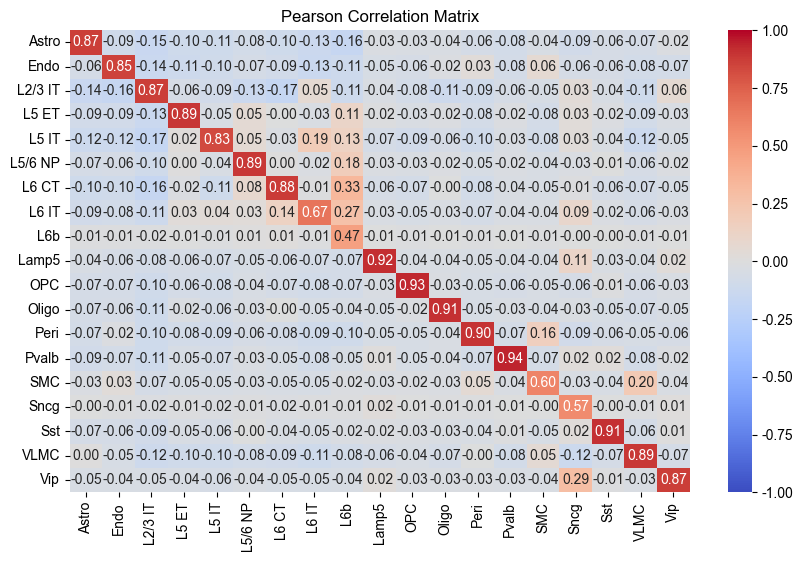

平均相关系数 (r): 0.8241


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

def compare_proportions(true_prop, pred_prop, plot=True):
    """
    比较真实与预测的细胞类型比例（Pearson相关系数）
    
    参数:
        true_prop (pd.DataFrame): 真实比例 (n_spots × n_celltypes)
        pred_prop (pd.DataFrame): 预测比例 (n_spots × n_celltypes)
        plot (bool): 是否绘制散点图
    
    返回:
        dict: 各细胞类型的Pearson相关系数及p值
        pd.DataFrame: 所有spot的相关系数矩阵
    """
    # 1. 验证输入
    assert isinstance(true_prop, pd.DataFrame) and isinstance(pred_prop, pd.DataFrame), "输入需为DataFrame"
    assert true_prop.shape == pred_prop.shape, "两个DataFrame形状需相同"
    assert (true_prop.columns == pred_prop.columns).all(), "细胞类型列名需一致"
    
    true_prop = pd.DataFrame(np.array(true_prop) / (np.array(true_prop).sum(axis=1, keepdims=True) + 1e-10), index=true_prop.index, columns=true_prop.columns)
    pred_prop = pd.DataFrame(np.array(pred_prop) / (np.array(pred_prop).sum(axis=1, keepdims=True) + 1e-10), index=pred_prop.index, columns=pred_prop.columns)

    true_prop = true_prop.fillna(0)
    pred_prop = pred_prop.fillna(0)
    # 2. 计算各细胞类型的Pearsonr
    results = {}
    for ct in true_prop.columns:
        r, p = pearsonr(true_prop[ct], pred_prop[ct])
        results[ct] = {'r': round(r, 4), 'p': round(p, 4)}
    
    # 3. 计算所有spot的整体相关性矩阵
    corr_matrix = pd.DataFrame(
        np.corrcoef(true_prop.T, pred_prop.T)[:len(true_prop.columns), len(true_prop.columns):],
        index=true_prop.columns,
        columns=pred_prop.columns
    )
    
    # 4. 可视化
    if plot:
        
        # 绘制相关性热图
        plt.figure(figsize=(10, 6))
        sns.heatmap(
            corr_matrix, 
            annot=True, 
            cmap='coolwarm', 
            vmin=-1, 
            vmax=1,
            fmt=".2f"
        )
        plt.title('Pearson Correlation Matrix')
        plt.show()
    
    return results, corr_matrix

true_prop = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1_gd_cells.csv", index_col=0)
# pred_prop = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250905/train_1427_epoch200.pt_target_props.csv", index_col=0) # batch scale
# pred_prop = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250904/train_2002_epoch200.pt_target_props.csv", index_col=0) # log1p + scale + batch scale
# pred_prop = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250905/train_1439_epoch200.pt_target_props.csv", index_col=0) # log1p + batch scale; 0.68
pred_prop = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_sp_pred_props.csv", index_col=0) # log1p + scale + batch scale



results, corr_matrix = compare_proportions(true_prop.T.loc[pred_prop.columns].T, pred_prop)

r_values = [v['r'] for v in results.values()]
# 计算平均值
mean_r = sum(r_values) / len(r_values)
print(f"平均相关系数 (r): {mean_r:.4f}")

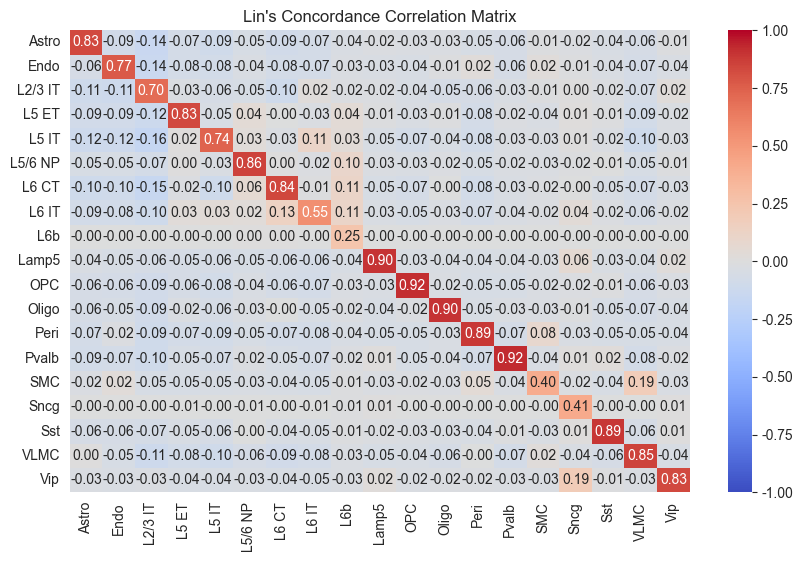

平均一致性相关系数 (CCC): 0.7519


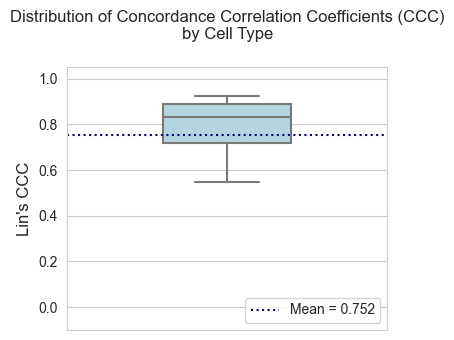


CCC Statistics by Cell Type:
             CCC
count  19.000000
mean    0.751905
std     0.201257
min     0.245800
25%     0.717800
50%     0.832700
75%     0.891050
max     0.924800

Cell Types Ranked by CCC:
CellType    CCC
   Pvalb 0.9248
     OPC 0.9197
   Oligo 0.9029
   Lamp5 0.9002
     Sst 0.8942
    Peri 0.8879
 L5/6 NP 0.8556
    VLMC 0.8520
   L6 CT 0.8437
     Vip 0.8327
   L5 ET 0.8319
   Astro 0.8298
    Endo 0.7680
   L5 IT 0.7353
 L2/3 IT 0.7003
   L6 IT 0.5481
    Sncg 0.4101
     SMC 0.4032
     L6b 0.2458


In [45]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

def lin_ccc(x, y):
    """
    计算Lin's Concordance Correlation Coefficient (CCC)
    
    参数:
        x, y: 两个需要比较的数值数组
        
    返回:
        ccc: 一致性相关系数 (范围[-1, 1])
    """
    x = np.asarray(x)
    y = np.asarray(y)
    cov = np.cov(x, y)[0, 1]
    x_mean, y_mean = np.mean(x), np.mean(y)
    x_var, y_var = np.var(x), np.var(y)
    
    # CCC计算公式
    numerator = 2 * cov
    denominator = x_var + y_var + (x_mean - y_mean)**2
    ccc = numerator / denominator
    return ccc

def compare_proportions(true_prop, pred_prop, plot=True):
    """
    比较真实与预测的细胞类型比例（使用Lin's CCC）
    
    参数:
        true_prop (pd.DataFrame): 真实比例 (n_spots × n_celltypes)
        pred_prop (pd.DataFrame): 预测比例 (n_spots × n_celltypes)
        plot (bool): 是否绘制散点图
    
    返回:
        dict: 各细胞类型的CCC值
        pd.DataFrame: 所有spot的CCC矩阵
    """
    # 1. 验证输入
    assert isinstance(true_prop, pd.DataFrame) and isinstance(pred_prop, pd.DataFrame), "输入需为DataFrame"
    assert true_prop.shape == pred_prop.shape, "两个DataFrame形状需相同"
    assert (true_prop.columns == pred_prop.columns).all(), "细胞类型列名需一致"
    
    # 2. 归一化处理
    true_prop = pd.DataFrame(np.array(true_prop) / (np.array(true_prop).sum(axis=1, keepdims=True) + 1e-10), 
                           index=true_prop.index, columns=true_prop.columns)
    pred_prop = pd.DataFrame(np.array(pred_prop) / (np.array(pred_prop).sum(axis=1, keepdims=True) + 1e-10),
                           index=pred_prop.index, columns=pred_prop.columns)
    
    true_prop = true_prop.fillna(0)
    pred_prop = pred_prop.fillna(0)
    
    # 3. 计算各细胞类型的CCC
    results = {}
    for ct in true_prop.columns:
        ccc = lin_ccc(true_prop[ct], pred_prop[ct])
        results[ct] = round(ccc, 4)
    
    # 4. 计算所有spot的整体CCC矩阵
    ccc_matrix = pd.DataFrame(
        np.zeros((len(true_prop.columns), len(pred_prop.columns))),
        index=true_prop.columns,
        columns=pred_prop.columns
    )
    
    for i, ct1 in enumerate(true_prop.columns):
        for j, ct2 in enumerate(pred_prop.columns):
            ccc_matrix.iloc[i, j] = lin_ccc(true_prop[ct1], pred_prop[ct2])
    
    # 5. 可视化
    if plot:
        plt.figure(figsize=(10, 6))
        sns.heatmap(
            ccc_matrix, 
            annot=True, 
            cmap='coolwarm', 
            vmin=-1, 
            vmax=1,
            fmt=".2f"
        )
        plt.title("Lin's Concordance Correlation Matrix")
        plt.show()
    
    return results, ccc_matrix

# 使用示例
true_prop = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1_gd_cells.csv", index_col=0)
pred_prop = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_sp_pred_props.csv", index_col=0) # log1p + scale + batch scale

results, ccc_matrix = compare_proportions(true_prop.T.loc[pred_prop.columns].T, pred_prop)

# 计算平均CCC
ccc_values = list(results.values())
mean_ccc = sum(ccc_values) / len(ccc_values)
print(f"平均一致性相关系数 (CCC): {mean_ccc:.4f}")

# 将CCC结果转换为DataFrame便于绘图
ccc_df = pd.DataFrame.from_dict(results, orient='index', columns=['CCC']).reset_index()
ccc_df.columns = ['CellType', 'CCC']

# 绘制箱线图
plt.figure(figsize=(4, 3.5))
sns.set_style("whitegrid")

# 主箱线图
ax = sns.boxplot(
    data=ccc_df,
    y='CCC',
    color='lightblue',
    width=0.4,
    showfliers=False,
    linewidth=1.5
)

# 添加统计参考线
median_ccc = ccc_df['CCC'].median()
mean_ccc = ccc_df['CCC'].mean()
# ax.axhline(median_ccc, color='royalblue', linestyle='--', linewidth=1.5, 
#            label=f'Median = {median_ccc:.3f}')
ax.axhline(mean_ccc, color='navy', linestyle=':', linewidth=1.5, 
           label=f'Mean = {mean_ccc:.3f}')

# # 添加数据点（按细胞类型着色）
# sns.stripplot(
#     data=ccc_df,
#     y='CCC',
#     x=np.zeros(len(ccc_df)),  # 将所有点放在同一垂直位置
#     hue='CellType',
#     palette='tab20',  # 使用多色区分细胞类型
#     alpha=0.8,
#     size=8,
#     jitter=0.2,
#     legend=False
# )

# 美化图形
plt.title('Distribution of Concordance Correlation Coefficients (CCC)\nby Cell Type', pad=20)
plt.ylabel("Lin's CCC", fontsize=12)
plt.xlabel('')  # 隐藏x轴标签
plt.ylim(-0.1, 1.05)  # CCC理论范围[-1,1]，实际生物数据通常>0
plt.legend(loc='lower right', frameon=True)

# # 添加数值标签
# for i, metric in enumerate(['Median', 'Mean']):
#     val = median_ccc if i == 0 else mean_ccc
#     ax.text(0.5, val + 0.02, f'{val:.3f}', 
#             ha='center', va='bottom', color='navy' if i else 'royalblue')

plt.tight_layout()
plt.show()

# 输出CCC统计摘要
print("\nCCC Statistics by Cell Type:")
print(ccc_df.describe().to_string())

# 按CCC排序输出细胞类型
print("\nCell Types Ranked by CCC:")
print(ccc_df.sort_values('CCC', ascending=False).to_string(index=False))

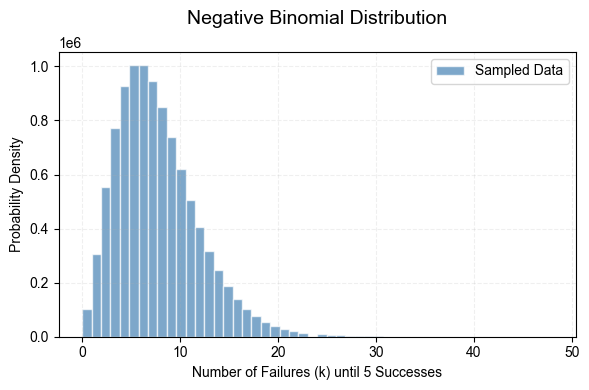

In [74]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import nbinom
import seaborn as sns

# 设置参数
n = 5       # 成功次数 (number of successes)
p = 0.4     # 单次成功概率 (success probability)
size = 10000000 # 样本量

# 生成负二项分布随机数 (模拟实验直到n次成功所需的失败次数)
data = nbinom.rvs(n=n, p=p, size=size)

# 创建画布
plt.figure(figsize=(6, 4))

# 绘制直方图 (归一化为概率密度)
plt.hist(data, 
         bins=50, 
        #  density=True, 
         alpha=0.7, 
         color='steelblue',
         edgecolor='white',
         label='Sampled Data')


# 美化图形
plt.title('Negative Binomial Distribution', pad=20, fontsize=14)
plt.xlabel('Number of Failures (k) until {} Successes'.format(n))
plt.ylabel('Probability Density')
plt.grid(alpha=0.2, linestyle='--')
plt.legend()
plt.tight_layout()

plt.show()

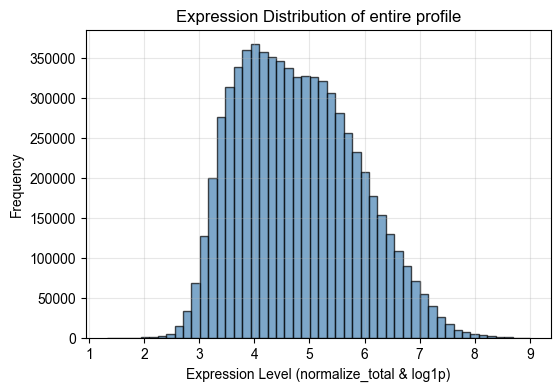

In [75]:
import scanpy as sc
import matplotlib.pyplot as plt

adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell/sc_adata_aligned.h5ad")
sc.pp.normalize_total(adata, target_sum=1e4)

sc.pp.log1p(adata)

# 选择一个基因
# gene = 'TP53'
expression_values = np.array(adata.to_df()).flatten()

non_zero_exp = expression_values[expression_values > 0]

plt.figure(figsize=(6, 4))
plt.hist(non_zero_exp, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
plt.title(f'Expression Distribution of entire profile')
plt.xlabel('Expression Level (normalize_total & log1p)')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

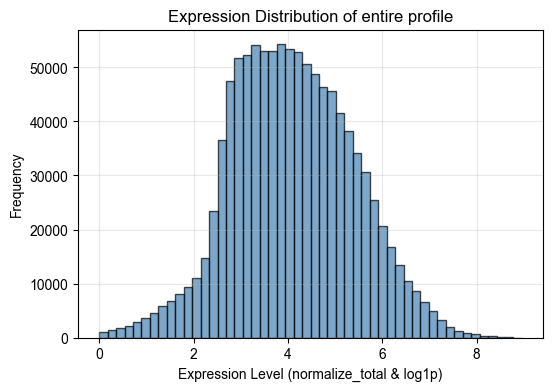

In [85]:
import scanpy as sc
import matplotlib.pyplot as plt

adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial/mouse1_sample1_aligned.h5ad")
sc.pp.normalize_total(adata, target_sum=1e4)

sc.pp.log1p(adata)

# 选择一个基因
# gene = 'TP53'
expression_values = np.array(adata.to_df()).flatten()

non_zero_exp = expression_values[expression_values > 0]

plt.figure(figsize=(6, 4))
plt.hist(non_zero_exp, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
plt.title(f'Expression Distribution of entire profile')
plt.xlabel('Expression Level (normalize_total & log1p)')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt

adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")
# sc.pp.normalize_total(adata, target_sum=1e4)

sc.pp.log1p(adata)

expression_values = np.array(adata.to_df()).flatten()

non_zero_exp = expression_values[expression_values > 0]

plt.figure(figsize=(6, 4))
plt.hist(non_zero_exp, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
plt.title(f'Expression Distribution of entire profile')
plt.xlabel('Expression Level (log1p)')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

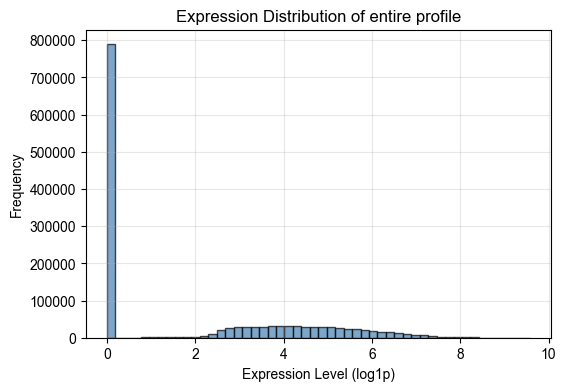

In [98]:
import scanpy as sc
import matplotlib.pyplot as plt

adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")
# sc.pp.normalize_total(adata, target_sum=1e4)
# sc.pp.filter_cells(adata, min_genes=200)    # 过滤基因数过少的细胞
# sc.pp.filter_genes(adata, min_cells=3)      # 过滤在极少数细胞中表达的基因

sc.pp.log1p(adata)

expression_values = np.array(adata.to_df()).flatten()

non_zero_exp = expression_values[expression_values > 0]

plt.figure(figsize=(6, 4))
plt.hist(expression_values, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
plt.title(f'Expression Distribution of entire profile')
plt.xlabel('Expression Level (log1p)')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

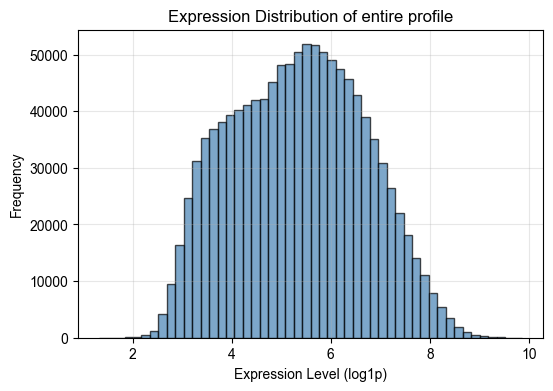

In [95]:
import scanpy as sc
import matplotlib.pyplot as plt

adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/outputs/training_data/pseudo_by_spots_10000_norm.h5ad")
# sc.pp.normalize_total(adata, target_sum=1e4)

sc.pp.log1p(adata)

expression_values = np.array(adata.to_df()).flatten()

non_zero_exp = expression_values[expression_values > 0]

plt.figure(figsize=(6, 4))
plt.hist(non_zero_exp, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
plt.title(f'Expression Distribution of entire profile')
plt.xlabel('Expression Level (log1p)')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

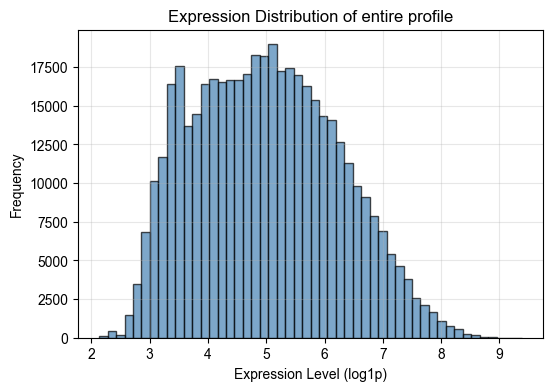

In [110]:
import scanpy as sc
import matplotlib.pyplot as plt

adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_spots.h5ad")
# sc.pp.normalize_total(adata, target_sum=1e4)

sc.pp.log1p(adata)

expression_values = np.array(adata.to_df()).flatten()

non_zero_exp = expression_values[expression_values > 0]

plt.figure(figsize=(6, 4))
plt.hist(non_zero_exp, 
         bins=50, 
         alpha=0.7, color='steelblue', edgecolor='black')
plt.title(f'Expression Distribution of entire profile')
plt.xlabel('Expression Level (log1p)')
plt.ylabel('Frequency')
plt.grid(alpha=0.3)
plt.show()

In [2]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from tqdm import tqdm

# 载入simu data_emd
simu_embeddings = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_simu_10000_embeddings.csv", index_col=0)

# 载入simu_adata
simu_spot_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/outputs/training_data/pseudo_by_spots_10000_norm.h5ad")
# sc.pp.normalize_total(simu_adata, target_sum=1e4)

# sc.pp.normalize_total(train_adata, target_sum=1e4)
simu_spot_adata.obs['spot_id'] = simu_spot_adata.obs.index  # 确保有spot_id列


# 载入target emd
sp_embeddings = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250904/train_2002_epoch200.pt_target_embeddings.csv", index_col=0)
sp_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")


# 3. 计算余弦相似度
print("Calculating cosine similarities...")
cos_sim = cosine_similarity(sp_embeddings, simu_embeddings) # spot * simu. spot

# 4. 生成预测结果（带细胞数量匹配）
print("Generating predictions with cell count matching...")
sp_pred_adata = sc.AnnData(
    X=csr_matrix((sp_adata.shape[0], sp_adata.shape[1])),
    obs=pd.DataFrame({
        'n_cells': sp_adata.obs["n_counts"],
        'matched_pseudo_spots': '',
        'avg_similarity': 0.0
    }, index=sp_adata.obs.index),
    var=simu_spot_adata.var.copy()
)

for i, target_spot in enumerate(tqdm(sp_adata.obs.index, desc="Processing spots")):
    target_n_cells = sp_pred_adata.obs.loc[target_spot, 'n_cells']
    
    # 步骤1：筛选细胞数量匹配的pseudo-spots
    valid_pseudo_mask = (simu_spot_adata.obs['n_cells'] == target_n_cells)
    valid_indices = np.where(valid_pseudo_mask)[0]
    
    # 步骤2：如果没有完全匹配，选择最接近的
    if len(valid_indices) == 0:
        cell_diffs = np.abs(simu_spot_adata.obs['n_cells'] - target_n_cells)
        closest_idx = np.argmin(cell_diffs)
        valid_indices = [closest_idx]
    
    # 步骤3：在匹配的pseudo-spots中找最相似的
    valid_cos_sim = cos_sim[i, valid_indices]
    best_match_idx = valid_indices[np.argmax(valid_cos_sim)]
    
    # 获取匹配的细胞
    matched_cells = simu_spot_adata[simu_spot_adata.obs.index[best_match_idx]]
    
    # 保存结果
    sp_pred_adata.X[i] = matched_cells.X.sum(axis=0)
    sp_pred_adata.obs.loc[target_spot, 'matched_pseudo_spots'] = simu_spot_adata.obs.index[best_match_idx]
    sp_pred_adata.obs.loc[target_spot, 'avg_similarity'] = cos_sim[i, best_match_idx]

# 6. 结果验证
print("\n=== Prediction Summary ===")
print(f"Total spots predicted: {sp_pred_adata.shape[0]}")
print(f"Genes: {sp_pred_adata.shape[1]}")
print(f"Average similarity: {sp_pred_adata.obs['avg_similarity'].mean():.4f}")

sp_pred_adata.write_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_spots.h5ad")

Calculating cosine similarities...
Generating predictions with cell count matching...


Processing spots: 100%|██████████| 5577/5577 [00:44<00:00, 126.61it/s]



=== Prediction Summary ===
Total spots predicted: 5577
Genes: 253
Average similarity: 0.6697


In [4]:

sp_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")
sp_pred_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_spots.h5ad")

# prepress of sp adata
sc.pp.log1p(sp_adata)
sc.pp.log1p(sp_pred_adata)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


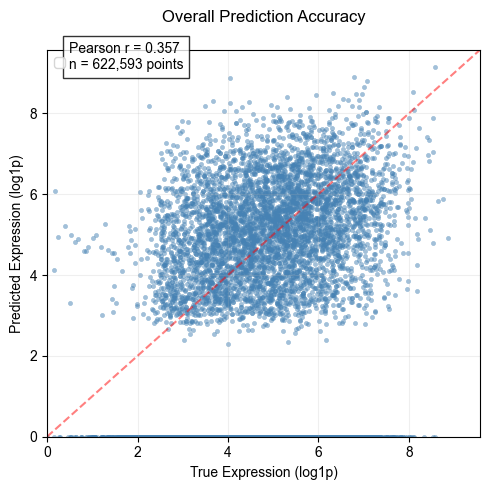

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
from scipy.stats import gaussian_kde
import scanpy as sc

# 将两个矩阵转换为DataFrame并展平
true_values = sp_adata.to_df().values.flatten()
pred_values = sp_pred_adata.to_df().values.flatten()

# 创建联合掩码（仅保留两个矩阵中均非零的位置）
nonzero_mask = (true_values > 0) #& (pred_values > 0)

# 提取非零值对
true_nonzero = true_values[nonzero_mask]
pred_nonzero = pred_values[nonzero_mask]

plot_df = pd.DataFrame({
    'True': true_nonzero,
    'Predicted': pred_nonzero
    
})

# # 1. 整体散点图
plt.figure(figsize=(5, 5))
sns.scatterplot(
    data=plot_df.sample(10000 if len(plot_df)>5000 else None, random_state=42),  # 下采样
    x='True',
    s=10,
    y='Predicted',
    alpha=0.5,
    color='steelblue',
    edgecolor=None
)


# 添加统计信息
pearson_r, _ = stats.pearsonr(plot_df['True'], plot_df['Predicted'])
plt.text(0.05, 0.95, 
         f'Pearson r = {pearson_r:.3f}\n'
         f'n = {len(plot_df):,} points',
         transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', alpha=0.8))

# 添加参考线
lims = [np.min([plot_df['True'].min(), plot_df['Predicted'].min()]), 
        np.max([plot_df['True'].max(), plot_df['Predicted'].max()])]

# lims = [-1, 
#         np.max([plot_df['True'].max(), plot_df['Predicted'].max()])]

plt.plot(lims, lims, 'r--', alpha=0.5, label='')
plt.xlim(lims)
plt.ylim(lims)

plt.title('Overall Prediction Accuracy', pad=20)
plt.xlabel('True Expression (log1p)')
plt.ylabel('Predicted Expression (log1p)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
# plt.savefig('overall_scatter.png', dpi=300, bbox_inches='tight')

plt.show()

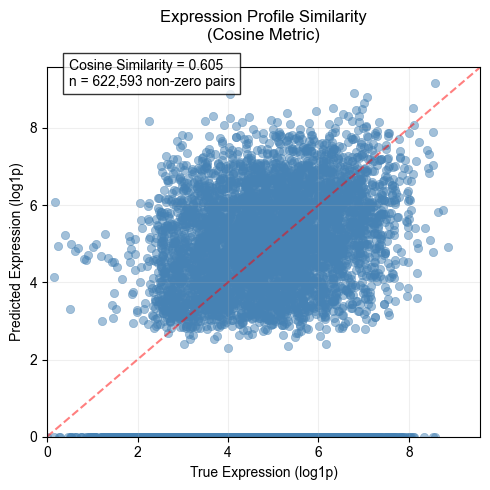

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from scipy import stats

# 将两个矩阵转换为DataFrame并展平
true_values = sp_adata.to_df().values.flatten()
pred_values = sp_pred_adata.to_df().values.flatten()

# 创建联合掩码（仅保留两个矩阵中均非零的位置）
nonzero_mask = (true_values > 0) #& (pred_values > 0)  # 根据需求决定是否要求预测值也非零

# 提取非零值对
true_nonzero = true_values[nonzero_mask]
pred_nonzero = pred_values[nonzero_mask]

plot_df = pd.DataFrame({
    'True': true_nonzero,
    'Predicted': pred_nonzero
})

# # ========== 计算余弦相似度 ========== #


# 计算余弦相似度
cos_sim = cosine_similarity(sp_adata.to_df(), np.array(sp_pred_adata.to_df()))
avg_cos_sim = np.mean(cos_sim.diagonal())  # 取对角线上的成对相似度

# ========== 可视化 ========== #
plt.figure(figsize=(5, 5))
sns.scatterplot(
    data=plot_df.sample(10000 if len(plot_df)>5000 else None, random_state=42),
    x='True',
    y='Predicted',
    alpha=0.5,
    color='steelblue',
    edgecolor=None
)

# 添加统计信息（替换为余弦相似度）
plt.text(0.05, 0.95, 
         f'Cosine Similarity = {avg_cos_sim:.3f}\n'
         f'n = {len(plot_df):,} non-zero pairs',
         transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', alpha=0.8))

# 添加参考线
lims = [np.min([plot_df['True'].min(), plot_df['Predicted'].min()]), 
        np.max([plot_df['True'].max(), plot_df['Predicted'].max()])]
plt.plot(lims, lims, 'r--', alpha=0.5)
plt.xlim(lims)
plt.ylim(lims)

plt.title('Expression Profile Similarity\n(Cosine Metric)', pad=20)
plt.xlabel('True Expression (log1p)')
plt.ylabel('Predicted Expression (log1p)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

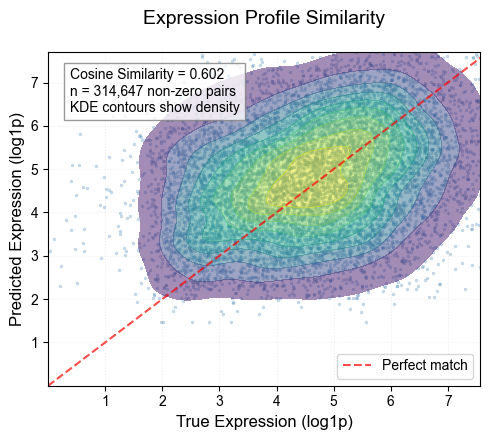

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from scipy import stats

sp_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")
sp_pred_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_spots.h5ad")

sc.pp.normalize_total(sp_adata)
sc.pp.normalize_total(sp_pred_adata)

# prepress of sp adata
sc.pp.log1p(sp_adata)
sc.pp.log1p(sp_pred_adata)

# 数据准备
true_values = sp_adata.to_df().values.flatten()
pred_values = sp_pred_adata.to_df().values.flatten()
nonzero_mask = (true_values > 0) & (pred_values > 0)  # 仅保留真实非零值
true_nonzero = true_values[nonzero_mask]
pred_nonzero = pred_values[nonzero_mask]

plot_df = pd.DataFrame({
    'True': true_nonzero,
    'Predicted': pred_nonzero
})

# 计算余弦相似度（样本层面）
cos_sim = cosine_similarity(sp_adata.to_df(), sp_pred_adata.to_df())
avg_cos_sim = np.mean(cos_sim.diagonal())

# ========== 核密度增强散点图 ========== #
plt.figure(figsize=(5, 4.5))

# 主散点图（带透明度）
main_scatter = sns.scatterplot(
    data=plot_df.sample(10000 if len(plot_df)>5000 else None, random_state=42),
    x='True',
    y='Predicted',
    alpha=0.3,
    color='steelblue',
    edgecolor=None,
    s=5  # 点大小
)
sns.kdeplot(
    data=plot_df.sample(10000 if len(plot_df)>5000 else None, random_state=42),
    x='True',
    y='Predicted',
    levels=10,  # 等高线层级数
    cmap='viridis',  # 红色渐变
    fill=True,  # 填充颜色
    alpha=0.5,  # 透明度
    thresh=0.05,  # 过滤低密度区域
    zorder=2  # 确保密度图在中层
)


# 添加参考线
lims = [np.min([plot_df['True'].min(), plot_df['Predicted'].min()]), 
        np.max([plot_df['True'].max(), plot_df['Predicted'].max()])]
plt.plot(lims, lims, 'r--', alpha=0.7, linewidth=1.5, label='Perfect match')

# 添加统计信息（带核密度说明）
stats_text = (
    f'Cosine Similarity = {avg_cos_sim:.3f}\n'
    f'n = {len(plot_df):,} non-zero pairs\n'
    f'KDE contours show density'
)
plt.text(
    0.05, 0.95, 
    stats_text,
    transform=plt.gca().transAxes,
    ha='left',
    va='top',
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray')
)

# 美化图形
plt.title('Expression Profile Similarity', pad=20, fontsize=14)
plt.xlabel('True Expression (log1p)', fontsize=12)
plt.ylabel('Predicted Expression (log1p)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(alpha=0.2, linestyle=':')

# 调整坐标轴范围（避免极端值影响可视化）
plt.xlim(lims[0], np.percentile(plot_df['True'], 99))
plt.ylim(lims[0], np.percentile(plot_df['Predicted'], 99))

plt.tight_layout()
plt.show()

In [ ]:
# sample-wise
# 计算每个样本的Pearson相关系数
sp_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")
sp_pred_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_spots.h5ad")

sc.pp.normalize_total(sp_adata)
sc.pp.normalize_total(sp_pred_adata)

# prepress of sp adata
sc.pp.log1p(sp_adata)
sc.pp.log1p(sp_pred_adata)

sample_correlation_results = []
for sample in sp_adata.obs_names:
    true_exp = sp_adata[sample, :].to_df().values.flatten()
    pred_exp = sp_pred_adata[sample, :].to_df().values.flatten()
    
    # 计算相关系数和p值
    r, p = stats.pearsonr(true_exp, pred_exp)
    
    # 计算R2
    slope, intercept, r_value, p_value, std_err = stats.linregress(true_exp, pred_exp)
    r2 = r_value**2
    
    sample_correlation_results.append({
        'Sample': sample,
        'Pearson_r': r,
        'R2': r2,
        'p_value': p
    })

# 转换为DataFrame
sample_corr_df = pd.DataFrame(sample_correlation_results)

plt.figure(figsize=(5, 4))
sns.set_style("whitegrid")

# 绘制箱线图
ax = sns.boxplot(
    data=sample_corr_df,
    y='Pearson_r',
    color='lightcoral',
    width=0.5,
    showfliers=False
)

# 添加统计信息
median_r = sample_corr_df['Pearson_r'].median()
mean_r = sample_corr_df['Pearson_r'].mean()
ax.axhline(median_r, color='red', linestyle='--', linewidth=1.5, label=f'Median = {median_r:.3f}')
ax.axhline(mean_r, color='blue', linestyle=':', linewidth=1.5, label=f'Mean = {mean_r:.3f}')

# 美化图形
plt.title('Distribution of Sample-wise Correlation Coefficients\n(Predicted vs True Expression)')
plt.ylabel("Pearson's r")
plt.legend(loc='lower right')

# 添加数据点
sns.stripplot(
    data=sample_corr_df,
    y='Pearson_r',
    color='darkred',
    alpha=0.6,
    size=1,
    jitter=True
)

plt.tight_layout()
plt.show()

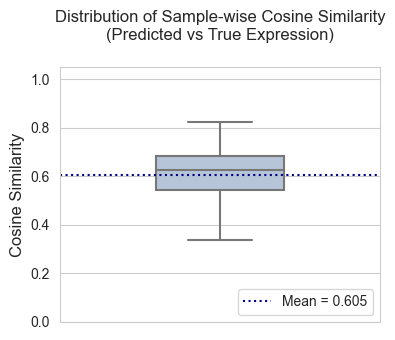


Cosine Similarity Statistics:
count    5577.000000
mean        0.604588
std         0.108172
min         0.069486
25%         0.545027
50%         0.624460
75%         0.683020
max         0.825112


In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from scipy import stats

# 加载数据
sp_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")
sp_pred_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_spots.h5ad")

# 数据预处理
sc.pp.normalize_total(sp_adata)
sc.pp.normalize_total(sp_pred_adata)
sc.pp.log1p(sp_adata)
sc.pp.log1p(sp_pred_adata)

# ========== 计算每个样本的余弦相似度 ========== #
sample_similarity_results = []
for sample in sp_adata.obs_names:
    # 获取当前样本的表达向量（形状: (1, n_genes)）
    true_exp = sp_adata[sample, :].to_df().values.reshape(1, -1)  # 必须为2D数组
    pred_exp = sp_pred_adata[sample, :].to_df().values.reshape(1, -1)
    
    # 计算余弦相似度
    cos_sim = cosine_similarity(true_exp, pred_exp)[0][0]
    
    # 计算R2（保留作为参考）
    slope, _, r_value, _, _ = stats.linregress(true_exp.flatten(), pred_exp.flatten())
    r2 = r_value**2
    
    sample_similarity_results.append({
        'Sample': sample,
        'Cosine_Similarity': cos_sim,
        'R2': r2  # 可选保留
    })

# 转换为DataFrame
sample_sim_df = pd.DataFrame(sample_similarity_results)

# ========== 可视化 ========== #
plt.figure(figsize=(4, 3.5))
sns.set_style("whitegrid")

# 绘制箱线图 + 数据点
ax = sns.boxplot(
    data=sample_sim_df,
    y='Cosine_Similarity',
    color='lightsteelblue',
    width=0.4,
    showfliers=False,
    linewidth=1.5
)

# 添加统计参考线
median_sim = sample_sim_df['Cosine_Similarity'].median()
mean_sim = sample_sim_df['Cosine_Similarity'].mean()
# ax.axhline(median_sim, color='royalblue', linestyle='--', linewidth=1.5, 
#            label=f'Median = {median_sim:.3f}')
ax.axhline(mean_sim, color='navy', linestyle=':', linewidth=1.5, 
           label=f'Mean = {mean_sim:.3f}')

# # 添加抖动点
# sns.stripplot(
#     data=sample_sim_df,
#     y='Cosine_Similarity',
#     color='darkblue',
#     alpha=0.1,
#     size=3,
#     jitter=0.2
# )

# 美化图形
plt.title('Distribution of Sample-wise Cosine Similarity\n(Predicted vs True Expression)', pad=20)
plt.ylabel("Cosine Similarity", fontsize=12)
plt.ylim(0, 1.05)  # 固定y轴范围（余弦相似度范围[0,1]）
plt.legend(loc='lower right', frameon=True)

# # 添加数值标签
# for i, metric in enumerate(['Median', 'Mean']):
#     val = median_sim if i == 0 else mean_sim
#     ax.text(0.5, val + 0.02, f'{val:.3f}', 
#             ha='center', va='bottom', color='navy' if i else 'royalblue')

plt.tight_layout()
plt.show()

# 输出统计摘要
print("\nCosine Similarity Statistics:")
print(sample_sim_df['Cosine_Similarity'].describe().to_string())

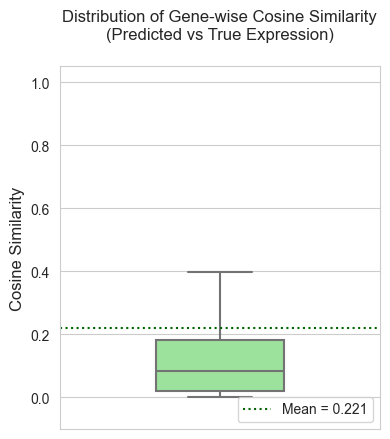


Gene-wise Cosine Similarity Statistics:
count    253.000000
mean       0.498024
std        0.866596
min       -1.000000
25%        0.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: Cosine_Similarity, dtype: float64


In [ ]:
# import numpy as np
# import pandas as pd
# import scanpy as sc
# import seaborn as sns
# import matplotlib.pyplot as plt
# from sklearn.metrics.pairwise import cosine_similarity
# from scipy import stats

# # 加载数据
# sp_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/data/processed/single_cell_spatial_to_spot/simulated_spotsize50/mouse1_sample1.h5ad")
# sp_pred_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_spots.h5ad")

# # 数据预处理
# sc.pp.normalize_total(sp_adata)
# sc.pp.normalize_total(sp_pred_adata)
# sc.pp.log1p(sp_adata)
# sc.pp.log1p(sp_pred_adata)

# sc.pp.scale(sp_adata)
# sc.pp.scale(sp_pred_adata)

# # 确保基因顺序一致
# assert all(sp_adata.var_names == sp_pred_adata.var_names), "基因顺序不一致，请先对齐"

# # ========== 计算每个基因的余弦相似度 ========== #
# gene_similarity_results = []
# for gene in sp_adata.var_names:
#     # 获取基因在所有样本中的表达向量（形状: (n_samples, 1)）
#     true_exp = sp_adata[:, gene].X.toarray().reshape(-1, 1)  # 必须为2D数组
#     pred_exp = sp_pred_adata[:, gene].X.toarray().reshape(-1, 1)
    
#     # 计算余弦相似度
#     cos_sim = cosine_similarity(true_exp, pred_exp)[0][0]
    
#     # 可选：计算R2作为参考
#     slope, _, r_value, _, _ = stats.linregress(true_exp.flatten(), pred_exp.flatten())
#     r2 = r_value**2
    
#     gene_similarity_results.append({
#         'Gene': gene,
#         'Cosine_Similarity': cos_sim,
#         'R2': r2  # 可选保留
#     })

# # 转换为DataFrame
# gene_sim_df = pd.DataFrame(gene_similarity_results)

# # ========== 可视化 ========== #
# plt.figure(figsize=(4, 4.5))
# sns.set_style("whitegrid")

# # 绘制箱线图
# ax = sns.boxplot(
#     data=gene_sim_df,
#     y='R2',
#     color='lightgreen',
#     width=0.4,
#     showfliers=False,
#     linewidth=1.5
# )

# # # 添加统计参考线
# # median_sim = gene_sim_df['Cosine_Similarity'].median()
# # mean_sim = gene_sim_df['Cosine_Similarity'].mean()
# # ax.axhline(median_sim, color='forestgreen', linestyle='--', linewidth=1.5, 
# #            label=f'Median = {median_sim:.3f}')
# ax.axhline(mean_sim, color='darkgreen', linestyle=':', linewidth=1.5, 
#            label=f'Mean = {mean_sim:.3f}')

# # # 添加抖动点（下采样避免过密）
# # plot_data = gene_sim_df.sample(min(1000, len(gene_sim_df)), random_state=42)
# # sns.stripplot(
# #     data=plot_data,
# #     y='Cosine_Similarity',
# #     color='green',
# #     alpha=0.6,
# #     size=4,
# #     jitter=0.2
# # )

# # 美化图形
# plt.title('Distribution of Gene-wise Cosine Similarity\n(Predicted vs True Expression)', pad=20)
# plt.ylabel("Cosine Similarity", fontsize=12)
# plt.ylim(-0.1, 1.05)  # 包含可能的负值
# plt.legend(loc='lower right', frameon=True)

# # # 添加数值标签
# # for i, metric in enumerate(['Median', 'Mean']):
# #     val = median_sim if i == 0 else mean_sim
# #     ax.text(0.5, val + 0.02, f'{val:.3f}', 
# #             ha='center', va='bottom', color='darkgreen' if i else 'forestgreen')

# plt.tight_layout()
# plt.show()

# # 输出统计摘要
# print("\nGene-wise Cosine Similarity Statistics:")
# print(gene_sim_df['Cosine_Similarity'].describe())

# # # 可选：保存高相似度和低相似度基因
# # top_genes = gene_sim_df.nlargest(10, 'Cosine_Similarity')
# # bottom_genes = gene_sim_df.nsmallest(10, 'Cosine_Similarity')
# # print("\nTop 10 genes with highest cosine similarity:")
# # print(top_genes[['Gene', 'Cosine_Similarity']])
# # print("\nBottom 10 genes with lowest cosine similarity:")
# # print(bottom_genes[['Gene', 'Cosine_Similarity']])

In [ ]:
# Create new adata for saving all single-cell level spot_id
sp_predicted_adata_by_cell = None
simu_sc_adata = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/outputs/training_data/pseudo_by_cells_10000_norm.h5ad")

for spot_id in sp_pred_adata.obs.index:
    try:
        # Get matched pseudo spot ID - ensure it's string type
        matched_pseudo_spot = str(sp_pred_adata.obs.loc[spot_id, 'matched_pseudo_spots'])
        
        # Extract corresponding single cell data - ensure comparison is with string
        mask = simu_sc_adata.obs['spot_id'].astype(str) == matched_pseudo_spot
        single_predicted_adata = simu_sc_adata[mask].copy()
        
        # Print progress (optional)
        print(f"Processing spot {spot_id} -> matched to pseudo spot {matched_pseudo_spot} "
              f"({single_predicted_adata.n_obs} cells)")

        # Generate unique cell IDs
        cell_ids = [f"{spot_id}_cell{i}" for i in range(single_predicted_adata.n_obs)]
        
        # Update observation metadata - ensure all new columns are string type
        single_predicted_adata.obs = single_predicted_adata.obs.assign(
            cell_id=cell_ids,
            spot_id=str(spot_id),  # Ensure spot_id is string
            matched_pseudo_spot=str(matched_pseudo_spot)  # Ensure this is string
        ).set_index('cell_id')
        
        # # Concatenate to the main object
        if sp_predicted_adata_by_cell is None:
            sp_predicted_adata_by_cell = single_predicted_adata
        else:
            import anndata
            sp_predicted_adata_by_cell = anndata.concat(
                [sp_predicted_adata_by_cell, single_predicted_adata],
                axis=0,
                join='outer',
                merge='unique'
            )
            
    except Exception as e:
        print(f"Error processing spot {spot_id}: {str(e)}")
        continue


sp_predicted_adata_by_cell.write_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp10/models/checkpoints/20250912/train_2020_epoch200.pt_predicted_by_cells.h5ad")    

Processing spot spot_0 -> matched to pseudo spot pseudo_spot_2088 (2 cells)
Processing spot spot_1 -> matched to pseudo spot pseudo_spot_9434 (2 cells)
Processing spot spot_2 -> matched to pseudo spot pseudo_spot_8735 (1 cells)
Processing spot spot_3 -> matched to pseudo spot pseudo_spot_4785 (1 cells)
Processing spot spot_4 -> matched to pseudo spot pseudo_spot_7858 (2 cells)
Processing spot spot_5 -> matched to pseudo spot pseudo_spot_8469 (1 cells)
Processing spot spot_6 -> matched to pseudo spot pseudo_spot_9140 (1 cells)
Processing spot spot_7 -> matched to pseudo spot pseudo_spot_5735 (2 cells)
Processing spot spot_8 -> matched to pseudo spot pseudo_spot_6347 (3 cells)
Processing spot spot_9 -> matched to pseudo spot pseudo_spot_5549 (1 cells)
Processing spot spot_10 -> matched to pseudo spot pseudo_spot_2963 (1 cells)
Processing spot spot_11 -> matched to pseudo spot pseudo_spot_3351 (3 cells)
Processing spot spot_12 -> matched to pseudo spot pseudo_spot_7462 (3 cells)
Processin

In [ ]:
# 读取abundance adata
# single-cell level
pseudo_mIHC_df = pd.read_csv("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/data/MERFISH/raw/mouse1_sample1_scores_normalized.csv", index_col=0)

# 读取spot-level abundance


In [71]:
# 根据spot_id进行对齐，并转换成cell_id level的prediction_adata
pred_image_adata_by_cell = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp9/results/checkpoints/20250903/train_2048_epoch20.pt_pseudo_10000_by_cell_with_image_embeddings.h5ad")

pred_exp_adata_by_cell = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp9/results/checkpoints/20250903/train_2048_epoch20.pt_predicted_by_cell_with_exp_embeddings.h5ad")

In [88]:
import torch
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from scipy.optimize import linear_sum_assignment  # 添加这个关键导入
    
def align_cells_within_spots(image_adata, exp_adata):
    """
    对齐同一spot内的单细胞
    Args:
        image_adata: 图像模态的AnnData (必须包含spot_id和cell_id)
        exp_adata: 表达模态的AnnData (必须包含spot_id和cell_id)
    Returns:
        对齐结果的DataFrame
    """
    # 1. 获取所有共享spot
    common_spots = set(image_adata.obs['spot_id']) & set(exp_adata.obs['spot_id'])
    
    # 2. 预计算所有细胞的embedding
    image_embs = _get_all_embeddings(image_adata, modality='image')
    exp_embs = _get_all_embeddings(exp_adata, modality='exp')
    
    # 3. 逐spot进行细胞对齐
    alignment_results = []
    for spot in common_spots:
        # 获取当前spot的细胞索引
        img_idx = image_adata.obs[image_adata.obs['spot_id'] == spot].index
        exp_idx = exp_adata.obs[exp_adata.obs['spot_id'] == spot].index
        
        # 提取当前spot的embedding
        spot_img_embs = image_embs.loc[img_idx]
        spot_exp_embs = exp_embs.loc[exp_idx]
        
        # 计算距离矩阵 (余弦距离)
        distances = 1 - cosine_similarity(spot_img_embs, spot_exp_embs)
        
        # 最优匹配 (匈牙利算法)
        row_ind, col_ind = linear_sum_assignment(distances)
        
        # 保存匹配结果
        for i, j in zip(row_ind, col_ind):
            alignment_results.append({
                'spot_id': spot,
                'image_cell_id': img_idx[i],
                'exp_cell_id': exp_idx[j],
                'distance': distances[i, j],
                'image_embedding': spot_img_embs.iloc[i].values,
                'exp_embedding': spot_exp_embs.iloc[j].values
            })
    
    return pd.DataFrame(alignment_results)

def _get_all_embeddings(adata, modality):
    """获取指定模态的所有细胞embedding"""
    if modality == 'image':
        
        embs = adata.obsm['image_embeddings']  # 假设图像特征已存储
    else:            
        embs = adata.obsm['exp_embeddings']
            
    return pd.DataFrame(embs, index=adata.obs.index)

alignment_df = align_cells_within_spots(pred_image_adata_by_cell, pred_exp_adata_by_cell)

# 将结果保存回AnnData
pred_image_adata_by_cell.obs['matched_cell'] = alignment_df.set_index('image_cell_id')['exp_cell_id']
pred_exp_adata_by_cell.obs['matched_cell'] = alignment_df.set_index('exp_cell_id')['image_cell_id']

In [ ]:
spatial_adata = pred_image_adata_by_cell.copy()

spatial_adata.obs[["x","y"]] = spatial_adata.obsm["spatial"].astype(float)


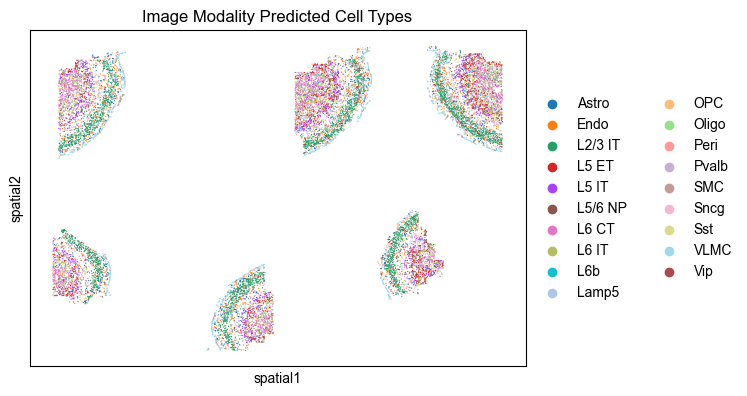

In [111]:
spatial_df = spatial_adata.obs[["spot_id","x","y"]].copy()
spatial_df = spatial_df.loc[pred_exp_adata_by_cell.obs['matched_cell'].values]

pred_exp_adata_by_cell.obsm["spatial"]  = spatial_df[["x","y"]].values

# visualization
sc.pl.spatial(pred_exp_adata_by_cell, color='celltype', spot_size=30, title='Image Modality Predicted Cell Types')

# read single-cell level ground truth
adata_gd = sc.read_h5ad("/aaa/zihanwu/yyyli2/project3_Spatial_DC_plus/exps/exp8/results/spatial_deconv_v4/high_res_adata_for_val.h5ad")

# align use index
adata_gd = adata_gd[pred_exp_adata_by_cell.obs['matched_cell'].values]

Visualization


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


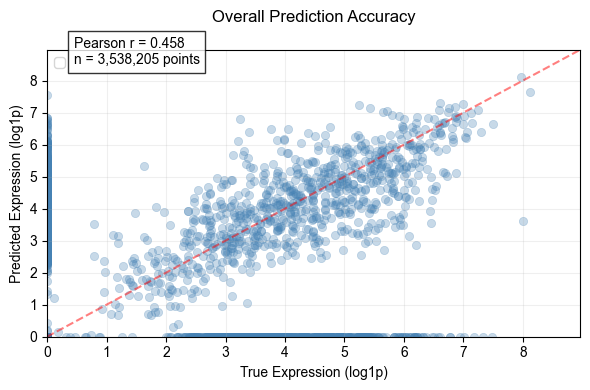

In [113]:
print("Visualization")

gd_adata_by_cell = adata_gd.copy()
pred_adata_by_cell = pred_exp_adata_by_cell.copy()

shared_genes = np.intersect1d(pred_adata_by_cell.var_names, gd_adata_by_cell.var_names)
pred_adata_by_cell = pred_adata_by_cell[:, shared_genes].copy()
gd_adata_by_cell = gd_adata_by_cell[:, shared_genes].copy()

# preprocess
sc.pp.normalize_total(gd_adata_by_cell, target_sum=1e4)
# sc.pp.normalize_total(pred_adata_by_cell, target_sum=1e4)

sc.pp.log1p(gd_adata_by_cell)
# sc.pp.log1p(pred_adata_by_cell)

# sc.pp.scale(mixed_adata_by_spot)
# sc.pp.scale(pred_adata_by_spot)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

plot_df = pd.DataFrame({
    'True': gd_adata_by_cell.to_df().values.flatten(),
    'Predicted': pred_adata_by_cell.to_df().values.flatten(),
    
})

# 1. 整体散点图
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=plot_df.sample(5000 if len(plot_df)>5000 else None, random_state=42),  # 下采样
    x='True',
    y='Predicted',
    alpha=0.3,
    color='steelblue',
    edgecolor=None
)

# 添加统计信息
pearson_r, _ = stats.pearsonr(plot_df['True'], plot_df['Predicted'])
plt.text(0.05, 0.95, 
         f'Pearson r = {pearson_r:.3f}\n'
         f'n = {len(plot_df):,} points',
         transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', alpha=0.8))

# 添加参考线
lims = [np.min([plot_df['True'].min(), plot_df['Predicted'].min()]), 
        np.max([plot_df['True'].max(), plot_df['Predicted'].max()])]
plt.plot(lims, lims, 'r--', alpha=0.5, label='')
plt.xlim(lims)
plt.ylim(lims)

plt.title('Overall Prediction Accuracy', pad=20)
plt.xlabel('True Expression (log1p)')
plt.ylabel('Predicted Expression (log1p)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
# plt.savefig('overall_scatter.png', dpi=300, bbox_inches='tight')

plt.show()